# Physics-consistency tests (full-domain surrogate)

The auxiliary losses (anomaly, gradient, correlation, spectral) are statistical/structural
priors; only non-negativity is an explicit hard physical constraint. This notebook checks
that the **trained** surrogate nonetheless behaves physically, by perturbing its inputs at
inference (no retraining) and verifying the response follows advection-diffusion intuition:

1. **Emission scaling** - PM2.5 should rise monotonically with emission, and fall to the
   background (not zero) when emission is removed.
2. **Wind-speed scaling** - stronger wind should dilute the near-source peak.
3. **Wind-direction rotation** - the plume should re-orient with the wind.

Tests 1-2 are **averaged over multiple test samples** (mean +/- sd) so the response is not
tied to one snapshot. All perturbations are applied in *physical* space (before log1p /
z-score) by wrapping the dataset accessors, keeping the normalisation pipeline consistent.

In [1]:
import sys, os; sys.path.insert(0, '../../src')
import numpy as np, torch, types, matplotlib.pyplot as plt
from pathlib import Path
from dataloader import PALMDatasetV2, N_Z
from model import UNet3DFiLM

OUT = Path('../../outputs')
hf = {'london_cm20190720-23': set(range(1, 25)),
      'london_cm20190820-23': set(range(25, 49)),
      'london_cm20190904-07': set(range(49, 73))}
ck = torch.load(OUT / 'full_domain_mask/checkpoints/best.pt', map_location='cpu', weights_only=False)
st = ck['norm_stats']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet3DFiLM(in_ch=19, spatial_ch=3, base_ch=16, dropout=0.0, n_z=12, use_attention=True, n_down=4)
model.load_state_dict(ck['model_state_dict']); model.to(DEVICE).eval()
MEAN = torch.tensor(st['pm25']['mean'][:12]).view(-1, 1, 1).to(DEVICE)
STD  = torch.tensor(st['pm25']['std'][:12]).view(-1, 1, 1).to(DEVICE)

ds = PALMDatasetV2(mask_input=True, normalise=True, hour_filter=hf, global_pm_norm=False,
                   em_bg_norm=True, t_hist=1, z_range=(0, 12)); ds._stats = st
ORIG_EM, ORIG_DYN = ds._get_emission_at, ds._get_dynamic_at   # to restore after patching

def predict(idx):
    x, y, mk = ds[idx]; msk = mk.numpy().astype(bool)
    with torch.no_grad():
        p = torch.expm1(model(x.unsqueeze(0).to(DEVICE))[0] * STD + MEAN).cpu().numpy()   # physical ug/m3
    return p, msk

os.makedirs('figs', exist_ok=True)
IDXS = list(range(len(ds)))                                  # all test samples (full average)
print('device =', DEVICE, '| averaging over', len(IDXS), 'of', len(ds), 'test samples')

# Figure font consistent with main text (Times New Roman; Liberation Serif is a
# metric-compatible fallback when Times New Roman is not installed).
import matplotlib as _mpl
_mpl.rcParams.update({'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'Nimbus Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.unicode_minus': False})

device = cuda | averaging over 72 of 72 test samples


## 1. Emission scaling

Multiply the physical emission field by `k` and measure PM2.5 at the emission hotspots
(top-1% emitting cells, lowest 3 levels), averaged over the sampled snapshots.
Expected: monotonic increase; `k=0` -> background.

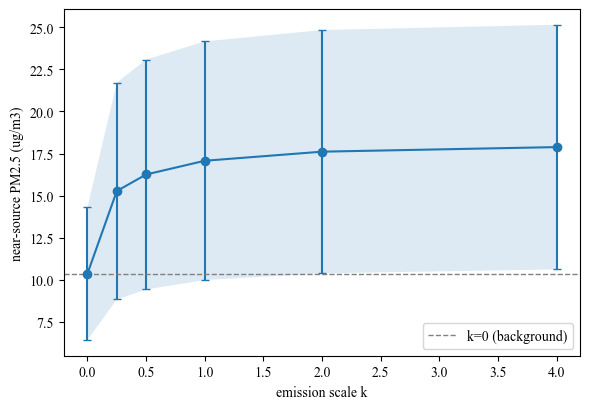

near-source mean: {0.0: 10.37, 0.25: 15.27, 0.5: 16.25, 1.0: 17.07, 2.0: 17.61, 4.0: 17.88}
monotonic increasing (mean): True
k=0 -> 10.37 ug/m3 (background, not zero)


In [2]:
def hot_cells(idx):
    sim, _, _, t_hour, _ = ds._index[idx]
    em = ORIG_EM(sim, t_hour)
    return em >= np.percentile(em, 99)

ks = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]
near_all = np.full((len(IDXS), len(ks)), np.nan)
for si, idx in enumerate(IDXS):
    hot = hot_cells(idx)
    for ki, k in enumerate(ks):
        ds._get_emission_at = types.MethodType(lambda self, s, t, k=k: ORIG_EM(s, t) * k, ds)
        p, msk = predict(idx); m3 = msk[:3] & hot[None]
        near_all[si, ki] = p[:3][m3].mean()
ds._get_emission_at = ORIG_EM                          # restore
near_m, near_sd = near_all.mean(0), near_all.std(0)

plt.figure(figsize=(6, 4.2))
plt.fill_between(ks, near_m - near_sd, near_m + near_sd, alpha=0.15)
plt.errorbar(ks, near_m, yerr=near_sd, fmt='o-', capsize=3)
plt.axhline(near_m[0], ls='--', c='grey', lw=1, label='k=0 (background)')
plt.xlabel('emission scale k'); plt.ylabel('near-source PM2.5 (ug/m3)')
plt.legend()
plt.tight_layout(); plt.savefig('figs/physics_emission.png', dpi=300, bbox_inches='tight'); plt.show()
print('near-source mean:', dict(zip(ks, np.round(near_m, 2))))
print('monotonic increasing (mean):', bool(np.all(np.diff(near_m) > 0)))
print('k=0 -> %.2f ug/m3 (background, not zero)' % near_m[0])

## 2. Wind-speed scaling (dilution)

Scale the physical wind (u, v) by `s`, averaged over the sampled snapshots.
Expected: stronger wind -> more dilution -> lower peak.

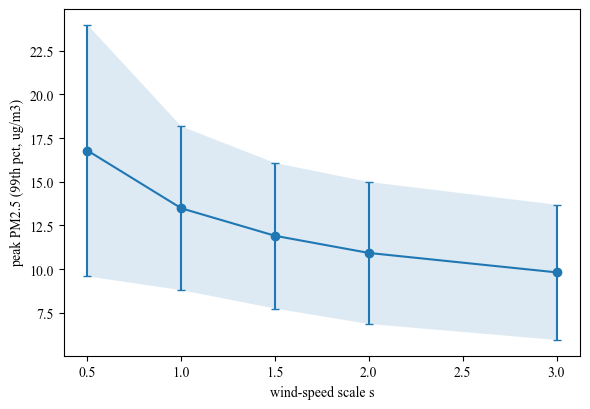

peaks mean: {0.5: 16.79, 1.0: 13.48, 1.5: 11.91, 2.0: 10.93, 3.0: 9.82}
peak drops 41.5% (mean) from weakest to strongest wind (dilution; saturates)


In [3]:
ss = [0.5, 1.0, 1.5, 2.0, 3.0]
pk_all = np.full((len(IDXS), len(ss)), np.nan)
for si, idx in enumerate(IDXS):
    for pi, s in enumerate(ss):
        def patched(self, sim, t, s=s):
            d = ORIG_DYN(sim, t).copy(); d[0:2 * N_Z] *= s; return d
        ds._get_dynamic_at = types.MethodType(patched, ds)
        p, msk = predict(idx); pk_all[si, pi] = np.percentile(p[msk], 99)
ds._get_dynamic_at = ORIG_DYN                          # restore
pk_m, pk_sd = pk_all.mean(0), pk_all.std(0)

plt.figure(figsize=(6, 4.2))
plt.fill_between(ss, pk_m - pk_sd, pk_m + pk_sd, alpha=0.15)
plt.errorbar(ss, pk_m, yerr=pk_sd, fmt='o-', capsize=3)
plt.xlabel('wind-speed scale s'); plt.ylabel('peak PM2.5 (99th pct, ug/m3)')
plt.tight_layout(); plt.savefig('figs/physics_wind_speed.png', dpi=300, bbox_inches='tight'); plt.show()
print('peaks mean:', dict(zip(ss, np.round(pk_m, 2))))
print('peak drops %.1f%% (mean) from weakest to strongest wind (dilution; saturates)'
      % (100 * (pk_m[0] - pk_m.min()) / pk_m[0]))

## Combined: emission + wind-speed scaling

First two tests side by side.

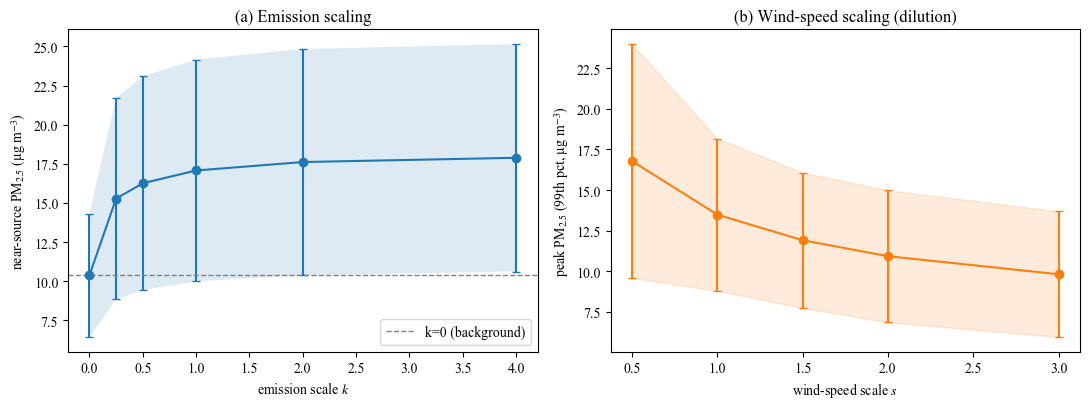

saved figs/physics_scaling.png


In [4]:
# Combined physics figure: (a) emission scaling + (b) wind-speed scaling
fig,(a1,a2)=plt.subplots(1,2,figsize=(11,4.2))
a1.fill_between(ks,near_m-near_sd,near_m+near_sd,alpha=0.15)
a1.errorbar(ks,near_m,yerr=near_sd,fmt='o-',capsize=3)
a1.axhline(near_m[0],ls='--',c='grey',lw=1,label='k=0 (background)')
a1.set_xlabel('emission scale $k$'); a1.set_ylabel('near-source PM$_{2.5}$ (µg m$^{-3}$)'); a1.legend()
a1.set_title('(a) Emission scaling',fontsize=12)
a2.fill_between(ss,pk_m-pk_sd,pk_m+pk_sd,alpha=0.15,color='C1')
a2.errorbar(ss,pk_m,yerr=pk_sd,fmt='o-',capsize=3,color='C1')
a2.set_xlabel('wind-speed scale $s$'); a2.set_ylabel('peak PM$_{2.5}$ (99th pct, µg m$^{-3}$)')
a2.set_title('(b) Wind-speed scaling (dilution)',fontsize=12)
fig.tight_layout(); fig.savefig('figs/physics_scaling.png',dpi=300,bbox_inches='tight'); plt.show()
print('saved figs/physics_scaling.png')

## 3. Wind-direction rotation

Rotate the physical wind vector (u, v) by theta and visualise the predicted plume at ~95 m
(above rooftops) for one representative sample. Expected: the plume re-orients with the wind.

rotation case: idx=41  london_cm20190820-23  2019-08-21 18:00


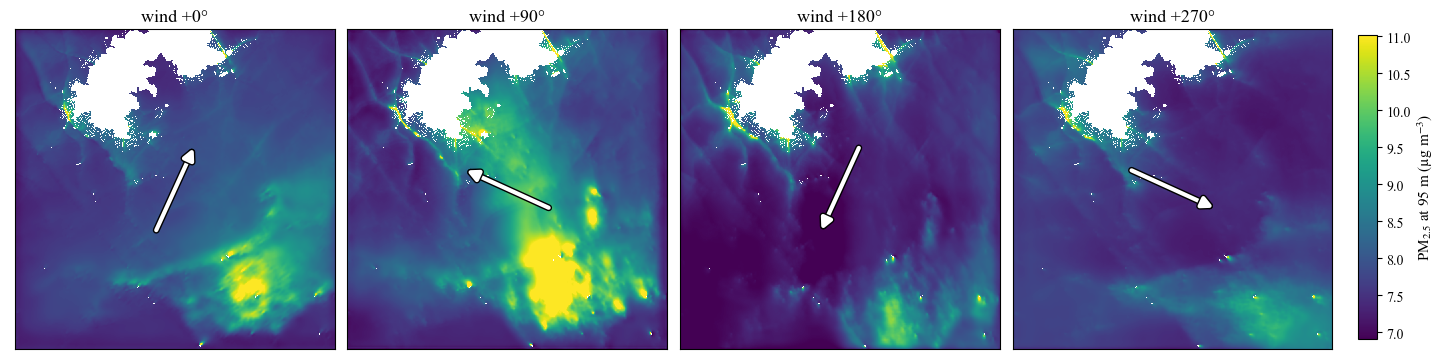

saved figs/physics_wind_dir.png


In [5]:
import matplotlib as mpl, copy as _copy
import matplotlib.patheffects as pe
def rotate(theta):
    c, sn = np.cos(theta), np.sin(theta)
    def patched(self, sim, t):
        d = ORIG_DYN(sim, t).copy(); u = d[0:N_Z].copy(); v = d[N_Z:2*N_Z].copy()
        d[0:N_Z] = c*u - sn*v; d[N_Z:2*N_Z] = sn*u + c*v; return d
    ds._get_dynamic_at = types.MethodType(patched, ds)
zlev = 6; degs = [0, 90, 180, 270]
idx = 41                                  # 2019-08-21 18:00 (similar overall concentration across orientations; plume mainly shifts position)
sim, _, _, t_hour, dt = ds._index[idx]
print(f"rotation case: idx={idx}  {sim}  {dt:%Y-%m-%d %H:%M}")
d0 = ORIG_DYN(sim, t_hour); u0 = float(np.nanmean(d0[zlev])); v0 = float(np.nanmean(d0[N_Z + zlev]))
fields = []
for deg in degs:
    rotate(np.deg2rad(deg)); p, msk = predict(idx); fields.append(np.where(msk[zlev], p[zlev], np.nan))
ds._get_dynamic_at = ORIG_DYN
allv = np.concatenate([f[np.isfinite(f)] for f in fields]); vmin, vmax = float(np.percentile(allv, 2)), float(np.percentile(allv, 99))
cmap = _copy.copy(mpl.cm.viridis); cmap.set_bad("white")
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6)); ny, nx = fields[0].shape
for a, deg, f in zip(ax, degs, fields):
    im = a.imshow(f, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax); a.set_xticks([]); a.set_yticks([]); a.set_title(f"wind +{deg}°", fontsize=13)
    th = np.deg2rad(deg); ur = np.cos(th)*u0 - np.sin(th)*v0; vr = np.sin(th)*u0 + np.cos(th)*v0; nrm = np.hypot(ur, vr) + 1e-9
    dx, dy = ur/nrm, vr/nrm; L = 0.30*nx; cx, cy = 0.5*nx, 0.5*ny
    a.annotate("", xy=(cx + 0.5*L*dx, cy + 0.5*L*dy), xytext=(cx - 0.5*L*dx, cy - 0.5*L*dy),
               arrowprops=dict(arrowstyle="-|>", color="white", lw=3.0, mutation_scale=16, path_effects=[pe.withStroke(linewidth=5.0, foreground="black")]))
fig.subplots_adjust(right=0.9, wspace=0.04); cax = fig.add_axes([0.915, 0.17, 0.011, 0.66]); cb = fig.colorbar(im, cax=cax)
cb.set_label("PM$_{2.5}$ at 95 m (µg m$^{-3}$)", fontsize=11)
fig.savefig("figs/physics_wind_dir.png", dpi=300, bbox_inches="tight"); plt.show()
print("saved figs/physics_wind_dir.png")

## Summary

Averaged over test samples, the surrogate's responses are physically consistent despite the
statistical loss terms:

- **Emission**: PM2.5 increases monotonically with emission and relaxes to the CAMS
  background (not zero) when emission is removed - the model separates the transported
  background from the local source. The response is sub-linear (the log1p transform and the
  training emission range compress the high-emission tail), which we note as a caveat.
- **Wind speed**: the near-source peak decreases with wind speed (dilution), saturating at
  high wind.
- **Wind direction**: the plume re-orients with the imposed wind.

These controlled-perturbation tests support the 'physics-guided' description at the level of
learned behaviour, complementing the architecture (surface-height emission placement, FiLM
conditioning on meteorology) and the emulated physics model (PALM).